# Implementation of a Variational Autoencoder, Step by Step (PyTorch)

# Learning Objectives

By the end of this notebook, you should be able to:

- explain the difference between a plain (deterministic) autoencoder and a variational autoencoder
- explain why a VAE encodes a **distribution** (mean and log-variance) instead of a single point in latent space
- implement the **reparameterization trick** and explain why it is necessary for backpropagation
- derive and implement the two components of the VAE loss (reconstruction + KL divergence)
- visualize and interpret a 2D latent space
- generate new, plausible digit images by sampling from the latent space
- discuss the role of the `beta` weighting factor in the VAE loss (beta-VAE)

# Libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets

print("PyTorch version:", torch.__version__)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

np.random.seed(42)
torch.manual_seed(42)

PyTorch version: 2.11.0+cu128
Using device: cuda


# Load and Prepare the MNIST Dataset

In [ ]:
train_dataset_raw = datasets.MNIST(root="./data", train=True, download=True)
test_dataset_raw = datasets.MNIST(root="./data", train=False, download=True)

x_train = (train_dataset_raw.data.numpy() / 255.0).astype("float32")
y_train = train_dataset_raw.targets.numpy()
x_test = (test_dataset_raw.data.numpy() / 255.0).astype("float32")
y_test = test_dataset_raw.targets.numpy()

print("x_train shape:", x_train.shape)
print("x_test shape:", x_test.shape)

100%|██████████| 9.91M/9.91M [00:00<00:00, 59.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.60MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.9MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.8MB/s]


x_train shape: (60000, 28, 28)
x_test shape: (10000, 28, 28)


# Hyperparameters

**Improvement / simplification over the original notebook:** in the Keras version, `batch_size` had to be **hardcoded into the model's `Input` layer** (`Input(batch_shape=(batch_size, 28, 28, 1))`), because the `noiser` function sampled Gaussian noise of a fixed shape `(batch_size, hidden_dim)`. This meant the trained model could only ever be used with that exact batch size at inference time (a real limitation e.g. for generating a single image).

In PyTorch, we sample noise with `torch.randn_like(mean)`, whose shape automatically matches whatever batch size is passed in — so the model works with **any** batch size, including 1, without any special handling.

In [ ]:
hidden_dim = 2   # size of the latent space (kept at 2 so we can visualize it directly, as in the original notebook)
batch_size = 128 # only used for training; the model itself is not tied to this value (see note above)

# Encoder

The encoder maps a `28 x 28` image to the parameters of a Gaussian distribution in latent space: a **mean** vector and a **log-variance** vector, both of size `hidden_dim`.

**Comment on `Dropout` + `BatchNorm`:** as in the original notebook, we apply `BatchNorm` followed by `Dropout` after each hidden dense layer, as a light regularization measure. This is not strictly necessary for a VAE (the KL term already acts as a regularizer), but it can help stabilize training on more complex datasets.

In [ ]:
class Encoder(nn.Module):
    def __init__(self, hidden_dim=2, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.BatchNorm1d(256),
            nn.Dropout(dropout),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.BatchNorm1d(128),
            nn.Dropout(dropout),
        )
        self.fc_mean = nn.Linear(128, hidden_dim)
        self.fc_log_var = nn.Linear(128, hidden_dim)

    def forward(self, x):
        h = self.net(x)
        mean = self.fc_mean(h)
        log_var = self.fc_log_var(h)
        return mean, log_var


encoder = Encoder(hidden_dim=hidden_dim).to(device)
print(encoder)

Encoder(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): Dropout(p=0.3, inplace=False)
    (5): Linear(in_features=256, out_features=128, bias=True)
    (6): ReLU()
    (7): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): Dropout(p=0.3, inplace=False)
  )
  (fc_mean): Linear(in_features=128, out_features=2, bias=True)
  (fc_log_var): Linear(in_features=128, out_features=2, bias=True)
)


# Latent Space — the Reparameterization Trick

Instead of directly outputting a latent vector, the encoder outputs a **mean** and a **log-variance**. We then *sample* a latent vector `z` from `N(mean, exp(log_var))`.

The problem: sampling is a **random, non-differentiable** operation, so gradients cannot flow back through it during backpropagation.

**The reparameterization trick** solves this by rewriting the sampling step as:

$$z = \text{mean} + e^{\text{log\_var}/2} \cdot \epsilon, \qquad \epsilon \sim \mathcal{N}(0, 1)$$

Now the randomness comes only from `epsilon`, which does not depend on the network's parameters — so gradients can flow through `mean` and `log_var` normally, while `epsilon` is just treated as a constant input at each forward pass.

**Improvement over the original notebook:** the original `noiser` function used **Python global variables** (`global mean, log_var`) to smuggle `mean`/`log_var` out of a Keras `Lambda` layer for use later in the loss function — a fragile pattern. In PyTorch, the encoder simply **returns** `mean` and `log_var` directly (see above), and the reparameterization step below only needs them as function arguments — no globals required.

In [ ]:
def reparameterize(mean, log_var):
    std = torch.exp(0.5 * log_var)
    eps = torch.randn_like(std)   # eps has the same shape and dtype/device as std automatically
    return mean + std * eps

# Decoder

The decoder takes a latent vector `z` of size `hidden_dim` and reconstructs a `28 x 28` image. The final `Sigmoid` activation ensures pixel outputs are in `[0, 1]`.

**Exercise:** build the decoder as the mirror image of the `Encoder` above — same layer sizes, reversed (`hidden_dim → 128 → 256 → 28*28`), each hidden layer followed by `ReLU`, `BatchNorm1d`, `Dropout(dropout)` (matching the encoder), and a final `Sigmoid` so pixel outputs land in `[0, 1]`. This is the same idea as `SimpleDecoder` / `DenoisingDecoder` from the Autoencoder lab, just with `BatchNorm`/`Dropout` added to mirror this encoder.

In [ ]:
class Decoder(nn.Module):
    def __init__(self, hidden_dim=2, dropout=0.3):
        super().__init__()
        # TODO: build self.net, mirroring the Encoder above:
        # Linear(hidden_dim, 128) -> ReLU -> BatchNorm1d(128) -> Dropout(dropout)
        # -> Linear(128, 256) -> ReLU -> BatchNorm1d(256) -> Dropout(dropout)
        # -> Linear(256, 28 * 28) -> Sigmoid
        self.net = nn.Sequential(
            # YOUR CODE HERE
        )

    def forward(self, z):
        # TODO: pass z through self.net, then reshape the output to (-1, 28, 28)
        # (same idea as SimpleDecoder.forward in the Autoencoder lab)
        pass


decoder = Decoder(hidden_dim=hidden_dim).to(device)
print(decoder)

# Full VAE Model

We assemble the encoder, the reparameterization step, and the decoder into a single `nn.Module`. The `forward` method returns everything the loss function needs: the reconstruction, and the `mean` / `log_var` used to compute the KL divergence.

In [ ]:
class VAE(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, x):
        mean, log_var = self.encoder(x)
        z = reparameterize(mean, log_var)
        reconstruction = self.decoder(z)
        return reconstruction, mean, log_var


vae = VAE(encoder, decoder).to(device)
total_params = sum(p.numel() for p in vae.parameters())
print(f"Total parameters: {total_params:,}")

Total parameters: 470,804


# Loss — the Evidence Lower Bound (ELBO)

The VAE is trained by maximizing the **Evidence Lower Bound (ELBO)**, or equivalently minimizing:

$$\mathcal{L} = \underbrace{\text{reconstruction loss}}_{\text{how well } x \text{ is reconstructed}} + \underbrace{D_{KL}(q(z|x) \, \| \, p(z))}_{\text{how close the latent distribution is to a standard normal}}$$

**Improvement over the original notebook:** the original reconstruction term was a raw **sum of squared errors** (`tf.reduce_sum(tf.square(x - y))`), which implicitly assumes a Gaussian decoder with a fixed, somewhat arbitrary variance. Since our decoder ends with a `Sigmoid` and pixel values are in `[0, 1]`, we instead use **binary cross-entropy** here, which corresponds to a *Bernoulli* likelihood — the more standard and better-motivated choice for MNIST-style pixel intensities, and the same choice we used for the plain autoencoders in the earlier lab.

**Improvement over the original notebook:** we also expose a `beta` weight on the KL term (as in **beta-VAE**). Setting `beta > 1` encourages a more disentangled, but less sharply reconstructed, latent space; `beta < 1` favors reconstruction quality over a clean latent structure. The original notebook used a fixed, implicit `beta = 1`; we keep `beta = 1` by default but make it explicit and easy to change.

In [ ]:
def vae_loss(recon_x, x, mean, log_var, beta=1.0):
    batch_size = x.size(0)

    recon_x_flat = recon_x.view(batch_size, -1)
    x_flat = x.view(batch_size, -1)

    # Reconstruction term: Bernoulli log-likelihood (binary cross-entropy), summed over pixels, averaged over the batch
    recon_loss = F.binary_cross_entropy(recon_x_flat, x_flat, reduction="sum") / batch_size

    # KL divergence between q(z|x) = N(mean, exp(log_var)) and the standard normal prior N(0, 1)
    kl_loss = -0.5 * torch.sum(1 + log_var - mean.pow(2) - log_var.exp(), dim=1)
    kl_loss = kl_loss.mean()

    total_loss = recon_loss + beta * kl_loss
    return total_loss, recon_loss, kl_loss

# Training Setup

**Exercise:** build `train_dataset` and `train_loader`, and define `optimizer` — same pattern as the Autoencoder lab: `TensorDataset` wrapping a single tensor (`x_train` — a VAE needs no separate labels/targets), a `DataLoader` with `shuffle=True`, and `optim.Adam(vae.parameters())`.

In [ ]:
# TODO: define optimizer = optim.Adam(vae.parameters())
optimizer = ...
beta = 1.0

# TODO: build train_dataset (TensorDataset wrapping torch.tensor(x_train))
# and train_loader (DataLoader, batch_size=batch_size, shuffle=True, drop_last=True)
train_dataset = ...
train_loader = ...

**Improvement over the original notebook:** rather than relying on Keras's default `.fit()` output (a single combined loss number per epoch), we track the **reconstruction loss** and **KL loss** separately at every epoch. This is very useful in practice: if the KL loss collapses to (near) zero early in training, it's a classic sign of **posterior collapse** (the decoder ignores the latent code entirely), while a KL loss that dominates the total loss suggests reconstructions may suffer.

**Exercise — the training loop:** complete `train_vae` below, adapting the training loop you built for `train_autoencoder` in the Autoencoder lab. The structure is the same (`zero_grad()` / forward / `backward()` / `step()`, batch-weighted running totals), with two differences: the model returns three values (`recon_x, mean, log_var`), and the loss comes from `vae_loss(...)`, which itself returns three values (`loss, recon_loss, kl_loss`) that must **all** be accumulated separately.

In [ ]:
def train_vae(model, train_loader, optimizer, device, epochs=25, beta=1.0):
    history = {"loss": [], "recon_loss": [], "kl_loss": []}

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        running_recon = 0.0
        running_kl = 0.0
        total = 0

        for (xb,) in train_loader:
            # TODO: training step (same pattern as train_autoencoder in the Autoencoder lab)
            # - move xb to device
            # - optimizer.zero_grad()
            # - recon_x, mean, log_var = model(xb)
            # - loss, recon_loss, kl_loss = vae_loss(recon_x, xb, mean, log_var, beta=beta)
            # - loss.backward()
            # - optimizer.step()
            # - accumulate running_loss, running_recon, running_kl (each: .item() * xb.size(0))
            #   and total (+= xb.size(0))
            pass

        history["loss"].append(running_loss / total)
        history["recon_loss"].append(running_recon / total)
        history["kl_loss"].append(running_kl / total)

        print(f"Epoch {epoch+1}/{epochs} - loss: {history['loss'][-1]:.2f} "
              f"- recon: {history['recon_loss'][-1]:.2f} - kl: {history['kl_loss'][-1]:.4f}")

    return history


epochs = 25
history = train_vae(vae, train_loader, optimizer, device, epochs=epochs, beta=beta)

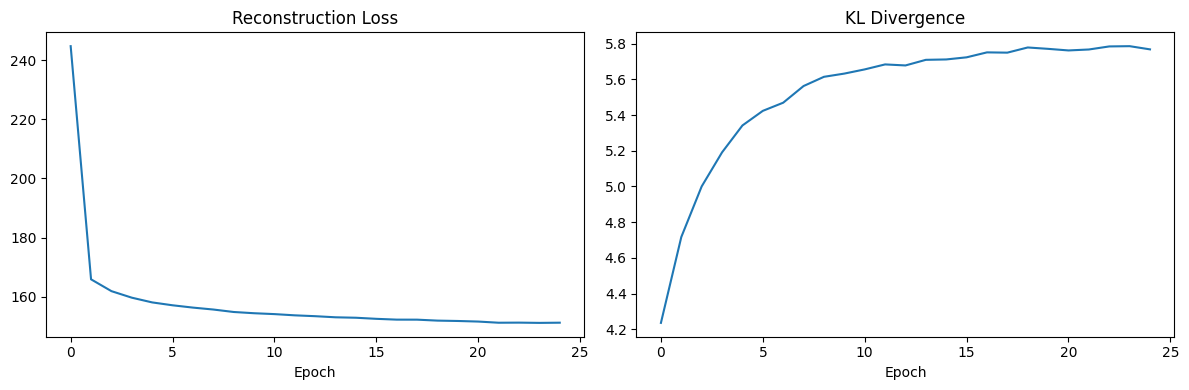

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history["recon_loss"])
plt.title("Reconstruction Loss")
plt.xlabel("Epoch")

plt.subplot(1, 2, 2)
plt.plot(history["kl_loss"])
plt.title("KL Divergence")
plt.xlabel("Epoch")

plt.tight_layout()
plt.show()

**Question:** does the KL loss stay near zero throughout training (a sign of posterior collapse), grow steadily, or stabilize at some intermediate value? What would you expect to see in each case?

# Latent Space

We encode a batch of test images and plot their `(mean_1, mean_2)` coordinates in the 2D latent space.

**Improvement over the original notebook:** the original scatter plot showed all points in a single color, with no way to tell which digit each point corresponds to. We color the points by their true digit label (available in `y_test`, even though the VAE itself never sees these labels during training) — this makes it possible to see whether the unsupervised latent space has spontaneously organized itself by digit identity.

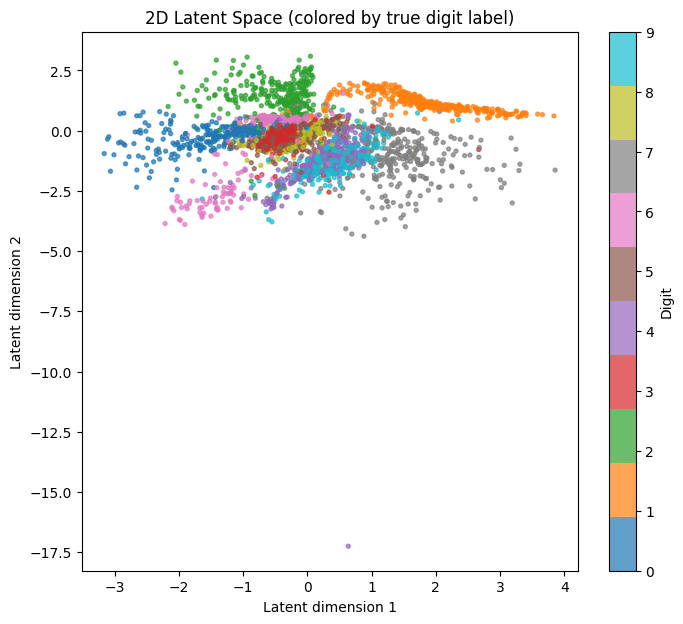

In [ ]:
vae.eval()
with torch.no_grad():
    x_sample = torch.tensor(x_test[:3000]).to(device)
    mean_sample, _ = vae.encoder(x_sample)
    h = mean_sample.cpu().numpy()

plt.figure(figsize=(8, 7))
scatter = plt.scatter(h[:, 0], h[:, 1], c=y_test[:3000], cmap="tab10", s=8, alpha=0.7)
plt.colorbar(scatter, label="Digit")
plt.xlabel("Latent dimension 1")
plt.ylabel("Latent dimension 2")
plt.title("2D Latent Space (colored by true digit label)")
plt.show()

# Results — Decoding a Single Point

We can pick an arbitrary point in latent space and decode it into an image, to see what the model generates there.

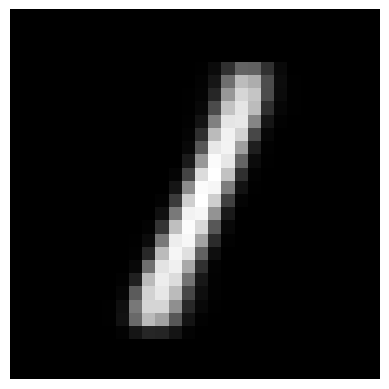

In [ ]:
vae.eval()
with torch.no_grad():
    z = torch.tensor([[0.94, 2.0]], dtype=torch.float32).to(device)
    image = vae.decoder(z).cpu().numpy()

plt.imshow(image.squeeze(), cmap="gray")
plt.axis("off")
plt.show()

# Results — Exploring the Latent Space Grid

We now decode a regular grid of points across the 2D latent space, to visualize how the generated digits change as we move continuously through the latent space. A smooth, meaningful transition between digit shapes (rather than abrupt jumps or unrelated blobs) is a good sign that the VAE has learned a well-structured latent space.

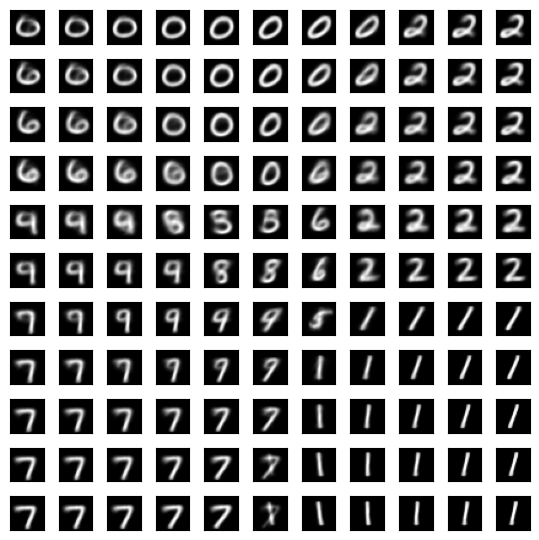

In [ ]:
n = 5
size = 2 * n + 1

plt.figure(figsize=(size / 2, size / 2))
num = 1

vae.eval()
with torch.no_grad():
    for i in range(-n, n + 1):
        for j in range(-n, n + 1):
            ax = plt.subplot(size, size, num)
            num += 1
            z = torch.tensor([[3 * i / n, 3 * j / n]], dtype=torch.float32).to(device)
            image = vae.decoder(z).cpu().numpy()
            plt.imshow(image.squeeze(), cmap="gray")
            ax.get_xaxis().set_visible(False)
            ax.get_yaxis().set_visible(False)

plt.tight_layout()
plt.show()

# Part 5 — Real-World Application: Generating New Digits

This is the defining ability of a **generative** model: creating new, plausible data that was never in the training set — the same underlying idea used for image/audio/text generation in practice. We explore two ways to use our VAE generatively:

1. **Sampling from the prior**: draw random points `z ~ N(0, I)` directly (not from encoding a real image) and decode them — exactly how the model is meant to be used at generation time.
2. **Latent space interpolation**: encode two real digits, then walk between their latent codes to see the model smoothly morph one digit into the other.

### Generating New Digits by Sampling from the Prior

**Exercise:** generate a grid of brand-new digit images:
- sample `z` from `torch.randn(n_samples, hidden_dim)` — this is exactly `N(0, I)`, the prior the KL term pushes the latent distribution toward during training
- decode `z` with `vae.decoder(z)`
- display the resulting images in a grid

In [ ]:
n_samples = 16

vae.eval()
with torch.no_grad():
    # TODO: sample z ~ N(0, I) of shape (n_samples, hidden_dim) using torch.randn, moved to `device`
    z = ...
    # TODO: decode z into images with vae.decoder(z)
    generated = ...

generated = generated.cpu().numpy()

plt.figure(figsize=(8, 8))
for i in range(n_samples):
    plt.subplot(4, 4, i + 1)
    plt.imshow(generated[i], cmap="gray")
    plt.axis("off")
plt.suptitle("New digits sampled from the prior N(0, I)")
plt.tight_layout()
plt.show()

### Interpolating Between Two Digits

**Exercise:** pick two real test images of different digits, encode both to get their latent `mean` (we use `mean` directly, not a reparameterized sample — we want one deterministic, repeatable point per image), then linearly interpolate between them and decode each intermediate point:

$$z_\alpha = (1 - \alpha) \cdot z_1 + \alpha \cdot z_2, \qquad \alpha \in [0, 1]$$

Complete the code below to build the interpolated latent points and decode each of them.

In [ ]:
digit_a, digit_b = 3, 8  # feel free to try other pairs, e.g. (4, 9) or (1, 0)

idx_a = np.where(y_test == digit_a)[0][0]
idx_b = np.where(y_test == digit_b)[0][0]

vae.eval()
with torch.no_grad():
    x_a = torch.tensor(x_test[idx_a:idx_a + 1]).to(device)
    x_b = torch.tensor(x_test[idx_b:idx_b + 1]).to(device)

    # TODO: encode x_a and x_b with vae.encoder(...) to get their mean vectors
    # (ignore log_var here — we only need one deterministic point per image)
    mean_a, _ = ...
    mean_b, _ = ...

n_steps = 10
alphas = np.linspace(0, 1, n_steps)

plt.figure(figsize=(16, 2))
with torch.no_grad():
    for i, alpha in enumerate(alphas):
        # TODO: compute z_alpha = (1 - alpha) * mean_a + alpha * mean_b
        z_alpha = ...
        image = vae.decoder(z_alpha).cpu().numpy()

        plt.subplot(1, n_steps, i + 1)
        plt.imshow(image.squeeze(), cmap="gray")
        plt.axis("off")
        plt.title(f"{alpha:.1f}")
plt.suptitle(f"Interpolating in latent space: {digit_a} -> {digit_b}")
plt.tight_layout()
plt.show()

### Discussion — Generation and Interpolation

1. Looking at the 16 generated digits, are they all equally legible? What determines whether a random `z` produces a clean, recognizable digit versus a blurry or ambiguous shape?
2. Does the transition between `digit_a` and `digit_b` look smooth (plausible intermediate shapes) or does it "jump" abruptly partway through? What does that tell you about the latent space learned by this VAE?
3. Try a pair of visually similar digits (e.g. `4` → `9`) versus a pair of very different digits (e.g. `1` → `0`). Does the interpolation quality differ?
4. Why couldn't we do this kind of meaningful interpolation/generation with a plain (non-variational) autoencoder from the earlier lab? *(Hint: think about what the KL term in the VAE loss encourages the latent space to look like, versus what a plain AE's loss encourages — or doesn't.)*
5. How does sampling from the prior (this section) relate to the manual latent-space grid you explored earlier in the notebook? Which one would you use to generate a *specific* digit on purpose, and which would you use to generate a random, diverse batch of digits?

# Final Questions

1. What is the fundamental difference between a plain (deterministic) autoencoder and a variational autoencoder, both in terms of architecture and in terms of what each is used for?
2. Why does the encoder output a `mean` **and** a `log_var`, instead of directly outputting a single latent vector `z`?
3. Explain in your own words why the reparameterization trick is necessary. What would go wrong if we sampled `z` directly from `N(mean, exp(log_var))` without it?
4. What does the KL divergence term in the loss actually encourage the model to do? What would likely happen to the latent space if this term were removed entirely (i.e. training with reconstruction loss only)?
5. What is "posterior collapse", and how could you detect it from the training curves plotted above?
6. What is the effect of increasing `beta` (e.g. `beta = 5`) on the trade-off between reconstruction quality and latent space structure? Try it and describe what you observe.
7. Why was `hidden_dim` set to `2` in this notebook? What would you gain and lose by increasing it to, say, `10` or `20`?
8. Looking at the latent space scatter plot colored by digit: do visually similar digits (e.g. `4` and `9`, or `3` and `8`) end up close to each other in latent space? Why might that happen even though the model never saw the labels during training?
9. In the latent space grid, do you observe smooth transitions between digit shapes as you move across the grid? What does a "smooth" versus "discontinuous" latent space tell you about what the model has learned?
10. What practical differences did you notice between the Keras and PyTorch versions of this notebook (e.g. handling of `mean`/`log_var` without global variables, batch-size independence, explicit reparameterization function, separate tracking of reconstruction vs. KL loss)?
11. In the generation exercise, what fraction of randomly sampled digits looked clean and recognizable versus ambiguous? What does this suggest about how tightly `hidden_dim = 2` forces 10 digit classes to share the same 2D space?

12. Relate the interpolation exercise back to the 2D latent scatter plot (colored by digit): does the interpolation path between two digits pass near or through the region occupied by a third, different digit? What would that mean for the generated images along the way?